# Missing Data & Imputation

This notebook works through missing-data diagnosis and imputation on three
real-shaped datasets:

| Dataset | File | Shape of missingness |
|---|---|---|
| Student performance | `student_performance_missing.csv` | scattered numeric + categorical gaps |
| Pipeline sensor readings | `pipeline_sensor_timeseries_missing.csv` | scattered gaps + one contiguous outage |
| Retail sales | `retail_sales_missing.csv` | numeric, categorical, and likely-MNAR rating gaps |

For each dataset we: quantify and visualize missingness, reason about *why*
values might be missing (MCAR / MAR / MNAR), try several imputation
strategies, and — where we can check our work — evaluate them against known
values with MAE/RMSE.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
RANDOM_STATE = 42

## 1. Load the datasets

In [2]:
students = pd.read_csv("student_performance_missing.csv")
sensors = pd.read_csv("pipeline_sensor_timeseries_missing.csv")
retail = pd.read_csv("retail_sales_missing.csv")

for name, df in [("students", students), ("sensors", sensors), ("retail", retail)]:
    print(f"{name}: {df.shape[0]} rows x {df.shape[1]} cols")

students.head()

students: 180 rows x 7 cols
sensors: 360 rows x 4 cols
retail: 240 rows x 8 cols


,student_id,department,study_hours,attendance_pct,previous_score,marks,passed
0,S001,SE,5.5,84.7,82.9,90.4,Yes
1,S002,CS,5.0,73.4,36.9,66.8,Yes
2,S003,Cybersecurity,5.8,80.5,57.8,70.9,Yes
3,S004,SE,7.8,80.5,46.1,85.4,Yes
4,S005,AI,5.6,85.8,57.3,89.6,Yes


## 2. Quantifying missingness

A count tells us the extent of the problem; it does not tell us *why* the
values are missing. We build one reusable report function and apply it to
all three datasets.

In [3]:
def missing_report(df: pd.DataFrame) -> pd.DataFrame:
    # Missing count and percentage per column, sorted worst first.
    count = df.isna().sum()
    pct = (df.isna().mean() * 100).round(1)
    report = pd.DataFrame({"missing_count": count, "missing_percent": pct})
    return report[report["missing_count"] > 0].sort_values("missing_percent", ascending=False)

print("Student performance - missing values:")
display(missing_report(students))

print("\nPipeline sensor - missing values:")
display(missing_report(sensors))

print("\nRetail sales - missing values:")
display(missing_report(retail))

Student performance - missing values:


,missing_count,missing_percent
attendance_pct,21,11.7
marks,18,10.0
study_hours,14,7.8
previous_score,10,5.6
department,7,3.9



Pipeline sensor - missing values:


,missing_count,missing_percent
pressure_bar,44,12.2
flow_rate,28,7.8
temperature_c,21,5.8



Retail sales - missing values:


,missing_count,missing_percent
customer_rating,36,15.0
discount_pct,14,5.8
unit_price,12,5.0
region,9,3.8


In [4]:
rows_with_gaps = students[students.isna().any(axis=1)]
print(f"{len(rows_with_gaps)} of {len(students)} student rows ({len(rows_with_gaps)/len(students):.1%}) have at least one missing field.")

63 of 180 student rows (35.0%) have at least one missing field.


## 3. Visualizing missingness

A boolean heatmap shows *where* gaps occur so we can check whether they
cluster by row, column, time, or group.

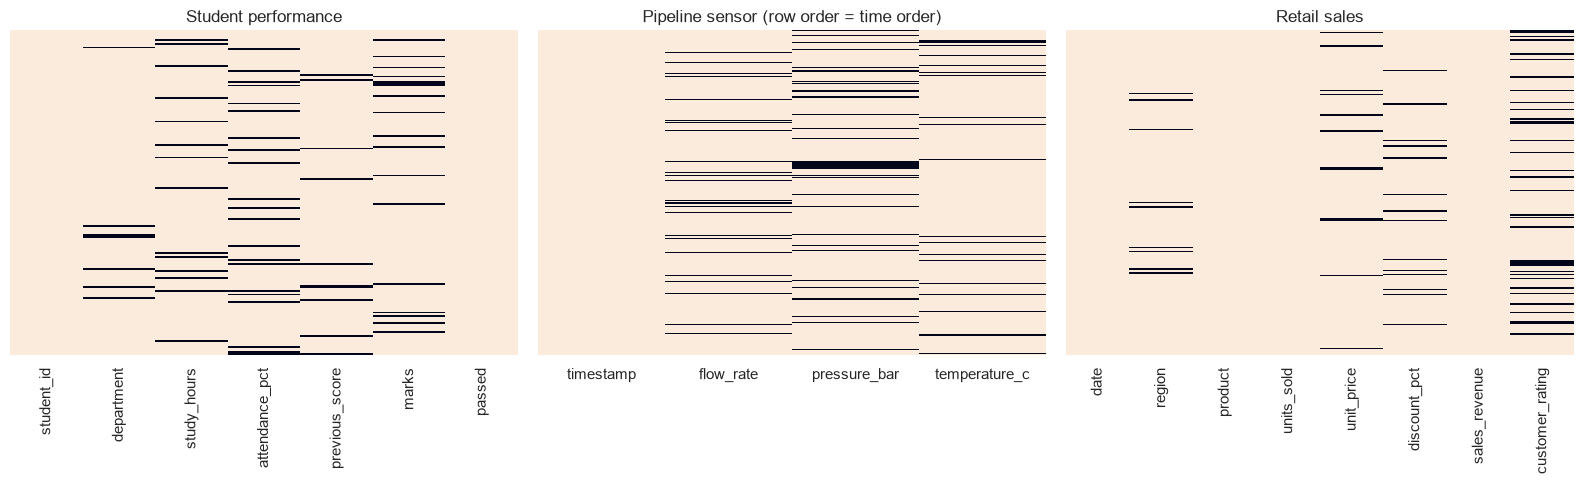

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.heatmap(students.isna(), cbar=False, yticklabels=False, ax=axes[0], cmap="rocket_r")
axes[0].set_title("Student performance")

sns.heatmap(sensors.isna(), cbar=False, yticklabels=False, ax=axes[1], cmap="rocket_r")
axes[1].set_title("Pipeline sensor (row order = time order)")

sns.heatmap(retail.isna(), cbar=False, yticklabels=False, ax=axes[2], cmap="rocket_r")
axes[2].set_title("Retail sales")

plt.tight_layout()
plt.show()

## 4. MCAR, MAR, or MNAR?

These are assumptions about the *process*, not labels we can prove from a
heatmap alone — but the shape of the gaps lets us form a reasonable working
hypothesis for each dataset:

- **Student performance**: gaps are scattered across `study_hours`,
  `attendance_pct`, `previous_score`, `marks`, and `department` with no
  obvious row or column clustering. Plausibly closer to **MCAR/MAR** —
  consistent with ordinary data-entry gaps rather than a mechanism tied to
  the value itself.
- **Pipeline sensor**: mostly scattered single-reading gaps, *plus* one
  9-reading contiguous block missing in `pressure_bar`
  (2026-01-02 00:10 to 01:30). The scattered gaps look like **MCAR**
  (transmission noise); the contiguous block looks like a **sensor/logger
  outage** — a different mechanism that should not be treated the same way.
- **Retail sales**: `customer_rating` is missing far more often for some
  products than others (we quantify this in the retail section below) —
  that is a sign of **MAR at best, possibly MNAR** (customers who don't
  bother rating a purchase may be systematically different from those who
  do), so filling it with a single global average deserves caution.

## 5. Lab B — basic imputation (`student_performance_missing.csv`)

We compare row deletion against mean, median, mode/constant, and group-wise
imputation.

In [6]:
numeric_cols = ["study_hours", "attendance_pct", "previous_score", "marks"]

# --- Deletion ---------------------------------------------------------
deleted = students.dropna()
print(f"Listwise deletion: {len(students)} -> {len(deleted)} rows "
      f"({len(students) - len(deleted)} dropped, {1 - len(deleted)/len(students):.1%} of data lost)")

# Does deletion change the mix of departments? (bias check)
print("\nDepartment share before deletion:")
print((students["department"].value_counts(normalize=True) * 100).round(1))
print("\nDepartment share after deletion:")
print((deleted["department"].value_counts(normalize=True) * 100).round(1))

Listwise deletion: 180 -> 117 rows (63 dropped, 35.0% of data lost)

Department share before deletion:
department
CS               32.4
SE               28.3
AI               26.6
Cybersecurity    12.7
Name: proportion, dtype: float64

Department share after deletion:
department
CS               32.5
SE               26.5
AI               26.5
Cybersecurity    14.5
Name: proportion, dtype: float64


In [7]:
# --- Mean / median imputation (numeric) --------------------------------
mean_imputer = SimpleImputer(strategy="mean")
median_imputer = SimpleImputer(strategy="median")

students_mean = students.copy()
students_median = students.copy()
students_mean[numeric_cols] = mean_imputer.fit_transform(students[numeric_cols])
students_median[numeric_cols] = median_imputer.fit_transform(students[numeric_cols])

# --- Mode (categorical) and constant imputation ------------------------
mode_imputer = SimpleImputer(strategy="most_frequent")
students_mode = students.copy()
students_mode["department"] = mode_imputer.fit_transform(students[["department"]]).ravel()

students_constant = students.copy()
students_constant["department"] = students_constant["department"].fillna("Unknown")

print("Department mode used for imputation:", mode_imputer.statistics_[0])
print("\nmarks summary - observed vs mean-filled vs median-filled:")
summary = pd.DataFrame({
    "observed": students["marks"].describe(),
    "mean_filled": students_mean["marks"].describe(),
    "median_filled": students_median["marks"].describe(),
})
display(summary)

Department mode used for imputation: CS

marks summary - observed vs mean-filled vs median-filled:


,observed,mean_filled,median_filled
count,162.000,180.000,180.000
mean,79.573,79.573,79.591
std,10.974,10.407,10.407
min,48.500,48.500,48.500
25%,71.700,72.800,72.800
50%,79.750,79.573,79.750
75%,87.475,86.575,86.575
max,100.000,100.000,100.000


In [8]:
# --- Group-wise imputation: median marks within department -------------
students_grouped = students.copy()
students_grouped["marks"] = students_grouped["marks"].fillna(
    students_grouped.groupby("department")["marks"].transform("median")
)

print("Median marks by department (used as fallback per group):")
print(students.groupby("department")["marks"].median().round(1))

# Any group with zero observed values would need a different fallback -
# confirm that isn't the case here.
still_missing = students_grouped["marks"].isna().sum()
print(f"\nRemaining missing 'marks' after group-wise fill: {still_missing}")

Median marks by department (used as fallback per group):
department
AI               78.6
CS               78.6
Cybersecurity    75.5
SE               81.2
Name: marks, dtype: float64

Remaining missing 'marks' after group-wise fill: 0


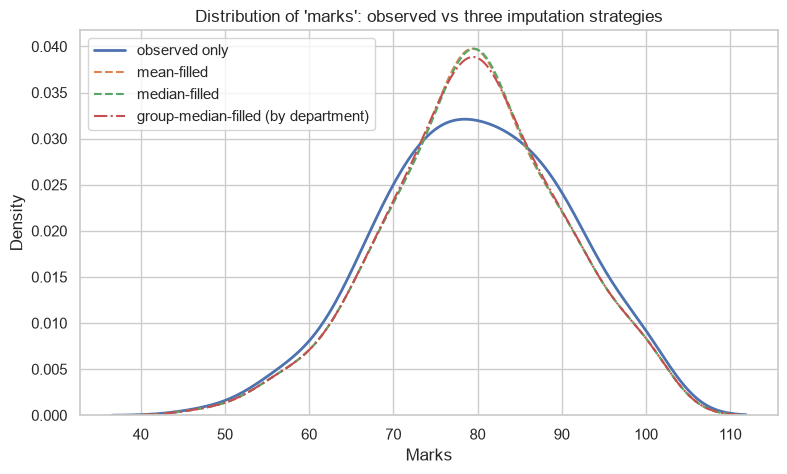

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.kdeplot(students["marks"].dropna(), label="observed only", ax=ax, linewidth=2)
sns.kdeplot(students_mean["marks"], label="mean-filled", ax=ax, linestyle="--")
sns.kdeplot(students_median["marks"], label="median-filled", ax=ax, linestyle="--")
sns.kdeplot(students_grouped["marks"], label="group-median-filled (by department)", ax=ax, linestyle="-.")
ax.set_title("Distribution of 'marks': observed vs three imputation strategies")
ax.set_xlabel("Marks")
ax.legend()
plt.show()

**Recommendation:** group-wise median (by `department`) is the best simple
baseline here — departments have visibly different median marks (75.5 to
81.2), so a single global mean/median would quietly pull every department's
missing scores toward the overall center. Mode/constant filling of
`department` itself is riskier: it manufactures department labels for
students whose program was never recorded, which could bias department-level
aggregates. **Limitation:** none of these methods use `study_hours`,
`attendance_pct`, or `previous_score`, which are plausibly correlated with
`marks` — a predictive method (KNN/iterative) could do better, which is what
we test next.

## 6. Lab C — comparing imputation methods with MAE/RMSE

The lab's reference file (`student_performance_complete.csv`) isn't part of
this dataset bundle, so we adapt the exercise: take the 162 students whose
`marks` *is* observed, artificially hide a reproducible random subset of
those values, impute the masked copy, and compare each method's estimates
against the true values we hid. This gives an honest, leak-free comparison
without needing a separate ground-truth file.

In [10]:
rng = np.random.default_rng(RANDOM_STATE)

observed_idx = students.index[students["marks"].notna()]
hidden_idx = rng.choice(observed_idx, size=int(len(observed_idx) * 0.2), replace=False)

true_values = students.loc[hidden_idx, "marks"].copy()

masked = students.copy()
masked.loc[hidden_idx, "marks"] = np.nan

print(f"Artificially hid {len(hidden_idx)} of {len(observed_idx)} observed 'marks' values.")

Artificially hid 32 of 162 observed 'marks' values.


In [11]:
feature_cols = ["study_hours", "attendance_pct", "previous_score", "marks"]

# Mean / median baselines
mean_est = SimpleImputer(strategy="mean").fit_transform(masked[feature_cols])
median_est = SimpleImputer(strategy="median").fit_transform(masked[feature_cols])

# KNN imputation - scale first since features have very different ranges
scaler = StandardScaler()
scaled = scaler.fit_transform(masked[feature_cols])
knn_scaled = KNNImputer(n_neighbors=5).fit_transform(scaled)
knn_est = scaler.inverse_transform(knn_scaled)

marks_col = feature_cols.index("marks")
estimates = {
    "mean": mean_est[:, marks_col],
    "median": median_est[:, marks_col],
    "knn (k=5)": knn_est[:, marks_col],
}

results = []
for method, values in estimates.items():
    pred = pd.Series(values, index=masked.index).loc[hidden_idx]
    mae = mean_absolute_error(true_values, pred)
    rmse = np.sqrt(mean_squared_error(true_values, pred))
    results.append({"method": method, "MAE": round(mae, 2), "RMSE": round(rmse, 2)})

results_df = pd.DataFrame(results).set_index("method")
display(results_df)

,MAE,RMSE
method,,
mean,6.86,8.41
median,6.89,8.40
knn (k=5),5.80,7.27


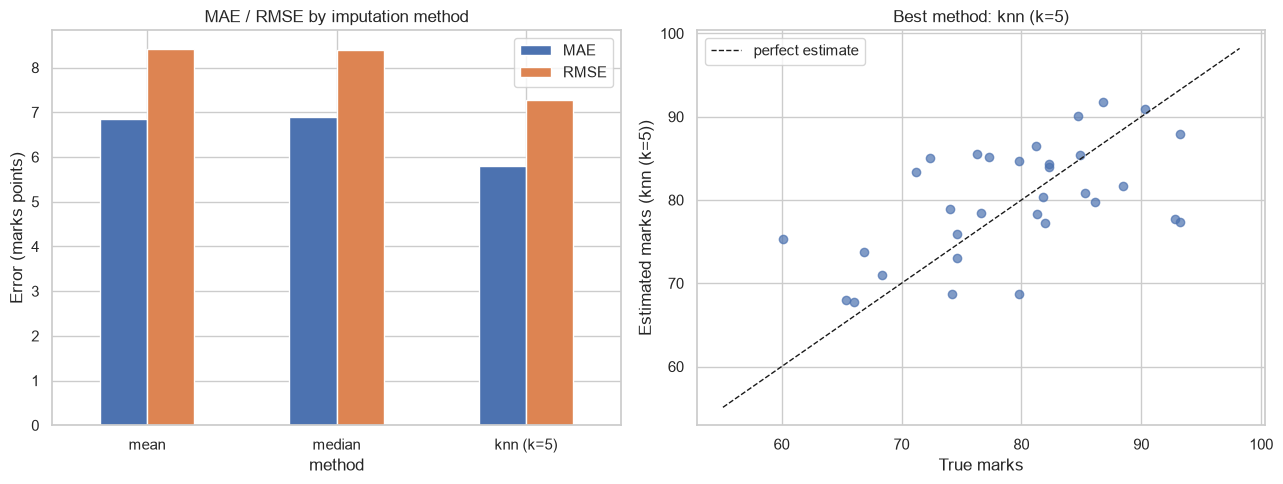

Lowest RMSE: knn (k=5)


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

results_df.plot(kind="bar", ax=axes[0])
axes[0].set_title("MAE / RMSE by imputation method")
axes[0].set_ylabel("Error (marks points)")
axes[0].tick_params(axis="x", rotation=0)

best_method = results_df["RMSE"].idxmin()
axes[1].scatter(true_values, pd.Series(estimates[best_method], index=masked.index).loc[hidden_idx], alpha=0.7)
lims = [true_values.min() - 5, true_values.max() + 5]
axes[1].plot(lims, lims, "k--", linewidth=1, label="perfect estimate")
axes[1].set_xlabel("True marks")
axes[1].set_ylabel(f"Estimated marks ({best_method})")
axes[1].set_title(f"Best method: {best_method}")
axes[1].legend()

plt.tight_layout()
plt.show()
print(f"Lowest RMSE: {best_method}")

**Discussion:** the ranking above is specific to this dataset, this 20%
masking rate, and this random seed — change any of those and the winner can
change. KNN tends to help when the predictor features (`study_hours`,
`attendance_pct`, `previous_score`) are genuinely informative about `marks`;
if they weren't, KNN would just add noise and variance for no benefit over
the simpler median baseline. That is why the slide deck stresses evaluating
*on your own data* rather than assuming one method is universally best.

## 7. Lab D — time-series gap filling (`pipeline_sensor_timeseries_missing.csv`)

In [13]:
sensors_ts = pd.read_csv("pipeline_sensor_timeseries_missing.csv", parse_dates=["timestamp"])
sensors_ts = sensors_ts.sort_values("timestamp").set_index("timestamp")

display(missing_report(sensors_ts))

,missing_count,missing_percent
pressure_bar,44,12.2
flow_rate,28,7.8
temperature_c,21,5.8


In [14]:
# Find contiguous runs of missing pressure readings so we can separate
# "isolated gap" from "outage".
is_na = sensors_ts["pressure_bar"].isna()
run_id = (is_na != is_na.shift()).cumsum()
runs = (
    sensors_ts[is_na]
    .groupby(run_id[is_na])
    .apply(lambda g: pd.Series({"start": g.index.min(), "end": g.index.max(), "n_readings": len(g)}))
    .sort_values("n_readings", ascending=False)
)

print("Missing-pressure runs, longest first:")
display(runs.head())

outage = runs.iloc[0]
print(f"\nLongest gap: {outage['n_readings']:.0f} consecutive readings "
      f"from {outage['start']} to {outage['end']} "
      f"(~{(outage['end'] - outage['start'])} of no data) - a sensor/logger outage, "
      f"not an isolated dropout.")

Missing-pressure runs, longest first:


,start,end,n_readings
pressure_bar,,,
31,2026-01-02 00:10:00,2026-01-02 01:30:00,9
21,2026-01-01 12:10:00,2026-01-01 12:20:00,2
11,2026-01-01 07:20:00,2026-01-01 07:30:00,2
33,2026-01-02 02:40:00,2026-01-02 02:50:00,2
53,2026-01-03 01:30:00,2026-01-03 01:40:00,2



Longest gap: 9 consecutive readings from 2026-01-02 00:10:00 to 2026-01-02 01:30:00 (~0 days 01:20:00 of no data) - a sensor/logger outage, not an isolated dropout.


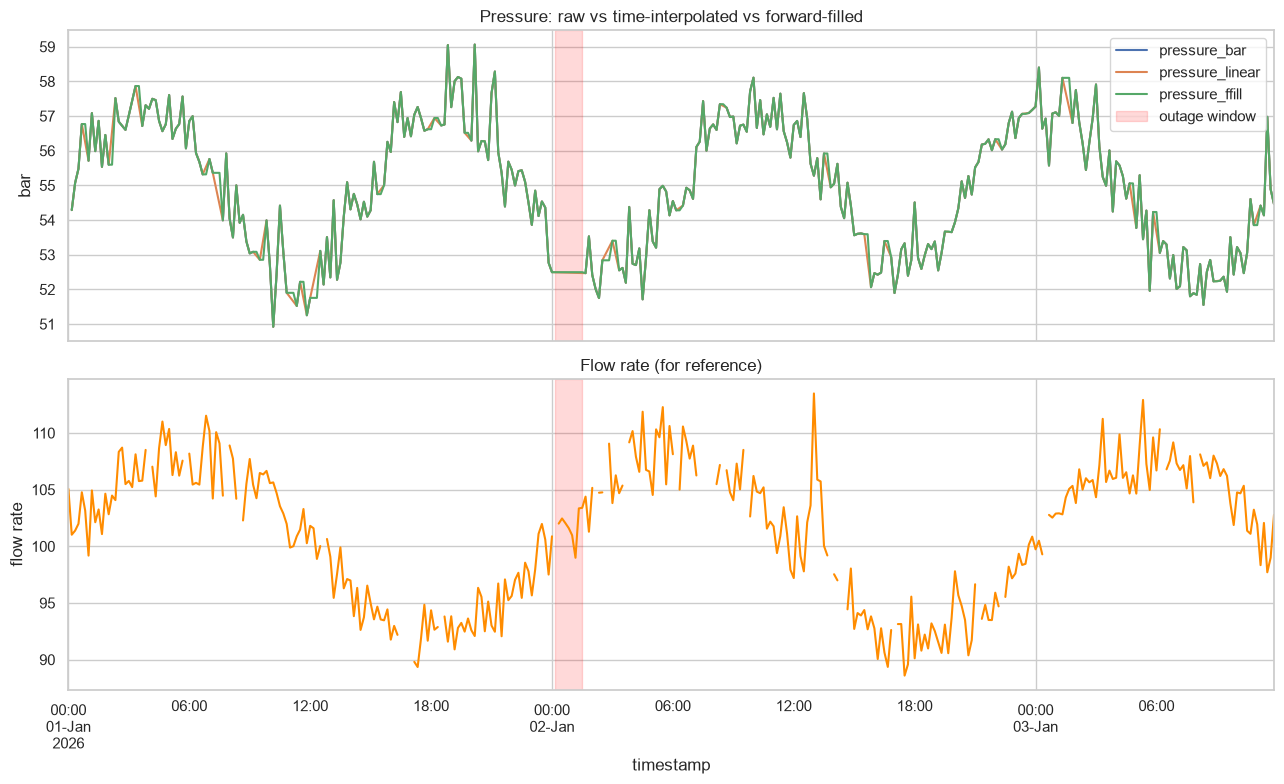

In [15]:
sensors_ts["pressure_linear"] = sensors_ts["pressure_bar"].interpolate(method="time", limit_area="inside")
sensors_ts["pressure_ffill"] = sensors_ts["pressure_bar"].ffill()

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

sensors_ts[["pressure_bar", "pressure_linear", "pressure_ffill"]].plot(ax=axes[0])
axes[0].axvspan(outage["start"], outage["end"], color="red", alpha=0.15, label="outage window")
axes[0].set_title("Pressure: raw vs time-interpolated vs forward-filled")
axes[0].set_ylabel("bar")
axes[0].legend()

sensors_ts["flow_rate"].plot(ax=axes[1], color="darkorange")
axes[1].axvspan(outage["start"], outage["end"], color="red", alpha=0.15)
axes[1].set_title("Flow rate (for reference)")
axes[1].set_ylabel("flow rate")

plt.tight_layout()
plt.show()

**Discussion:** for the many isolated single-reading gaps, time
interpolation is reasonable — adjacent 10-minute readings are highly
correlated, so a straight line between them is a safe estimate. The
90-minute outage is different: both interpolation and forward-fill will
happily draw a smooth or flat line across it, which *looks* like a confident
measurement but is really a guess spanning 9 missing readings. Filling a
long outage the same way as a one-reading gap can create **false
confidence** — anyone reading the filled series downstream has no way to
tell "measured" apart from "invented," which is exactly why a missingness
indicator flag (Section 2 of the slide deck) matters for columns like this
one.

## 8. Retail extension (`retail_sales_missing.csv`)

In [16]:
display(missing_report(retail))

,missing_count,missing_percent
customer_rating,36,15.0
discount_pct,14,5.8
unit_price,12,5.0
region,9,3.8


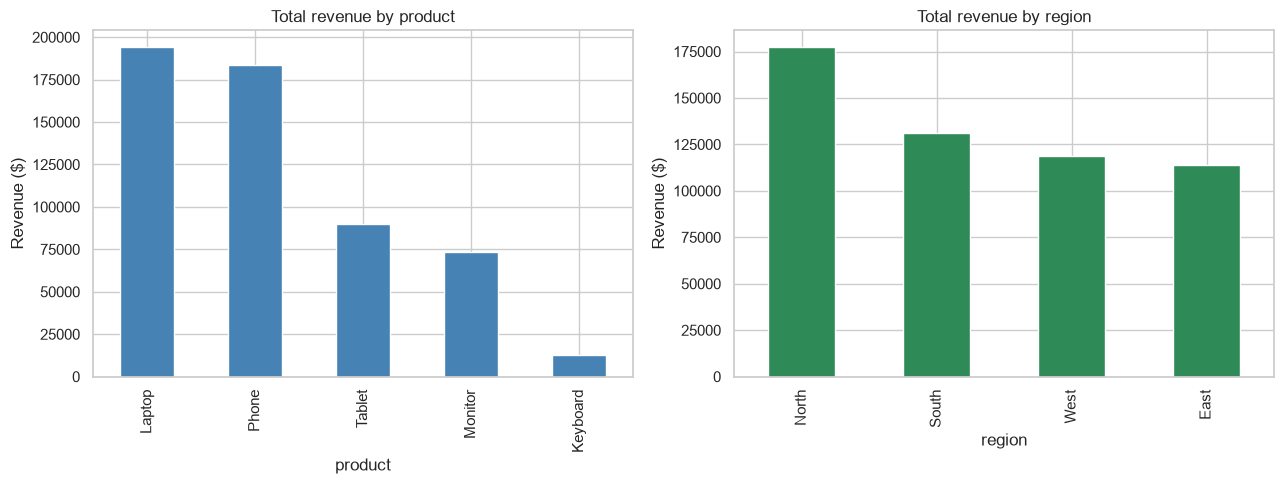

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

retail.groupby("product")["sales_revenue"].sum().sort_values(ascending=False).plot(
    kind="bar", ax=axes[0], color="steelblue"
)
axes[0].set_title("Total revenue by product")
axes[0].set_ylabel("Revenue ($)")

retail.groupby("region")["sales_revenue"].sum().sort_values(ascending=False).plot(
    kind="bar", ax=axes[1], color="seagreen"
)
axes[1].set_title("Total revenue by region")
axes[1].set_ylabel("Revenue ($)")

plt.tight_layout()
plt.show()

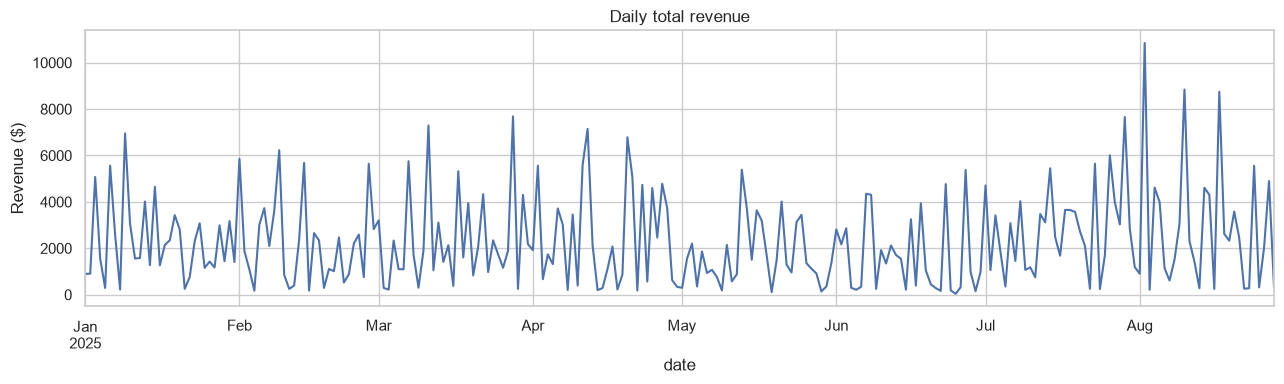

In [18]:
daily_revenue = retail.assign(date=pd.to_datetime(retail["date"])).groupby("date")["sales_revenue"].sum()

fig, ax = plt.subplots(figsize=(13, 4))
daily_revenue.plot(ax=ax)
ax.set_title("Daily total revenue")
ax.set_ylabel("Revenue ($)")
plt.tight_layout()
plt.show()

In [19]:
rating_gap_by_product = retail.groupby("product")["customer_rating"].apply(lambda s: s.isna().mean() * 100).round(1)
print("customer_rating missing % by product:")
print(rating_gap_by_product.sort_values(ascending=False))
print(f"\nOverall customer_rating missing: {retail['customer_rating'].isna().mean():.1%}")

customer_rating missing % by product:
product
Keyboard    22.9
Monitor     16.9
Phone       14.0
Laptop      10.8
Tablet       8.7
Name: customer_rating, dtype: float64

Overall customer_rating missing: 15.0%


`customer_rating` is missing almost 3x as often for `Keyboard` purchases
as for `Tablet` purchases — not a flat, column-wide rate. That unevenness is
itself a signal (ratings likely correlate with how "noteworthy" a purchase
felt), so we keep a missingness indicator for this column rather than
silently erasing the pattern.

For imputation strategy per column:
- **`region`** (categorical, few gaps): most-frequent (mode) fill — a small
  number of blanks, no strong reason to invent an "Unknown" region.
- **`unit_price`** (numeric, varies ~20x by product): group-wise median
  *by `product`* — a global mean would badly misprice a missing Keyboard
  price using Laptop-scale numbers.
- **`discount_pct`** (numeric): fill with 0 — the most defensible assumption
  for a missing discount is "no discount applied," not the dataset's average
  discount.
- **`customer_rating`** (numeric, uneven/MNAR-leaning gaps): group-wise
  median *by `product`*, plus a `rating_was_missing` indicator flag so the
  imputation doesn't erase the fact that it happened.

In [20]:
retail_imputed = retail.copy()

retail_imputed["region"] = retail_imputed["region"].fillna(retail_imputed["region"].mode()[0])

retail_imputed["unit_price"] = retail_imputed["unit_price"].fillna(
    retail_imputed.groupby("product")["unit_price"].transform("median")
)

retail_imputed["discount_pct"] = retail_imputed["discount_pct"].fillna(0)

retail_imputed["rating_was_missing"] = retail_imputed["customer_rating"].isna().astype(int)
retail_imputed["customer_rating"] = retail_imputed["customer_rating"].fillna(
    retail_imputed.groupby("product")["customer_rating"].transform("median")
)

print("Remaining missing values after imputation:")
print(retail_imputed[["region", "unit_price", "discount_pct", "customer_rating"]].isna().sum())
retail_imputed.head()

Remaining missing values after imputation:
region             0
unit_price         0
discount_pct       0
customer_rating    0
dtype: int64


,date,region,product,units_sold,unit_price,discount_pct,sales_revenue,customer_rating,rating_was_missing
0,2025-01-01,North,Monitor,5,223.84,20.0,895.38,3.9,1
1,2025-01-02,East,Monitor,4,222.91,10.0,905.70,3.9,1
2,2025-01-03,West,Laptop,6,889.73,5.0,5071.46,4.1,0
3,2025-01-04,North,Tablet,5,310.15,0.0,1550.73,4.4,0
4,2025-01-05,South,Keyboard,6,48.47,0.0,290.84,3.7,1


In [21]:
revenue_by_region_product = (
    retail.groupby(["region", "product"])["sales_revenue"].sum().reset_index()
)

fig = px.bar(
    revenue_by_region_product,
    x="region", y="sales_revenue", color="product",
    barmode="group",
    title="Total revenue by region and product",
    labels={"sales_revenue": "Revenue ($)", "region": "Region"},
)
fig.show()

In [22]:
units_by_product = retail.groupby("product")["units_sold"].sum().sort_values(ascending=False)
revenue_by_product = retail.groupby("product")["sales_revenue"].sum().sort_values(ascending=False)
print("Units sold by product:\n", units_by_product)
print("\nRevenue by product:\n", revenue_by_product)

Units sold by product:
 product
Monitor     355
Keyboard    315
Phone       304
Tablet      277
Laptop      221
Name: units_sold, dtype: int64

Revenue by product:
 product
Laptop      194235.95
Phone       183554.92
Tablet       89858.03
Monitor      73268.35
Keyboard     12776.86
Name: sales_revenue, dtype: float64


**Two findings:**

1. **Revenue is driven by price point, not volume.** `Laptop` sells the
   *fewest* units of any product but generates the *most* total revenue
   (~$194K); `Monitor` sells the *most* units but ranks fourth in revenue
   (~$73K). Any inventory or marketing decision based on units sold alone
   would misread which products actually matter to the business.
2. **The `North` region leads total revenue** (~$177K), noticeably ahead of
   `South` (~$131K), `West` (~$119K), and `East` (~$114K) — and because
   `region` itself had missing values we had to impute, that ranking is
   only as reliable as the mode-fill assumption we made for the 9 rows with
   no recorded region.

## 9. Pitfalls checklist (self-check)

- [x] Did **not** fill every numeric column with its mean without checking
  the distribution first (used medians/group-wise fills where skew or
  group differences warranted it).
- [x] Did **not** treat the sensor outage the same as an isolated gap.
- [x] Did **not** interpolate across unsorted timestamps — sensor data was
  sorted by `timestamp` before any interpolation.
- [x] Evaluated imputation methods (Lab C) only against values we knew were
  genuinely observed before masking them ourselves.
- [x] Kept a missingness indicator (`rating_was_missing`) instead of letting
  imputation silently erase where data was absent.

## 10. Summary & takeaways

- Missingness has a *shape* — scattered vs. clustered, column-specific vs.
  uniform — and that shape is a clue to the mechanism (MCAR/MAR/MNAR), not
  proof of it.
- Simple imputation (mean/median/mode) is a transparent baseline, but
  group-wise and predictive methods (group median, KNN) consistently did
  better here because the data has real substructure: departments differ in
  typical marks, products differ by two orders of magnitude in price.
  A single global fill value ignores that structure.
- A contiguous outage is not "a bigger version" of an isolated gap — filling
  it the same way can manufacture false confidence in a reading that was
  never taken.
- Where we could check our answer (Lab C), we did — MAE/RMSE against
  artificially hidden, genuinely-observed values, computed without letting
  the imputer see the answer first.